# CrusherCal, afirmación BS-1: validación con retención y banda predictiva, medida, incluido dónde falla el protocolo dentro de la muestra

**Pregunta:** ¿Sobrevive la habilidad de tonelaje del protocolo con retención de CrusherCal cuando se remuestrean los muestreos, y está su banda predictiva de 80 por ciento calibrada fuera de la muestra, hasta donde pueden decirlo diez muestreos?

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los notebooks 01, 02 y 03 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook usted puede:

- enunciar la afirmación BS-1 del documento de diseño del producto y decir qué evidencia la respaldaría y cuál la refutaría;
- mostrar las dos conclusiones que alcanza el protocolo dentro de la muestra del estado del arte y que el protocolo con retención revierte;
- probar la robustez de la habilidad de tonelaje sobre todos los subconjuntos de siete muestreos de diez;
- medir dos veces la banda predictiva de 80 por ciento, dentro de la muestra y anidada fuera de la muestra, y decir cuál es cuál;
- enunciar lo que este notebook no puede mostrar de la afirmación.

## Preparación

Numpy y matplotlib. Las combinaciones de muestreos y las probabilidades binomiales de la cobertura usan solo la biblioteca estándar.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones son el lector de muestreos, el constructor del modelo base y el módulo CrusherCal, con `itertools` para los subconjuntos y `math` para los coeficientes binomiales.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import itertools
import math
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# Solo funciones públicas del pipeline: el notebook no define ningún método propio
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, loo
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos del HP500. Propietario: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las diez filas de muestreos se transcriben de la Tabla A1 del artículo. Archivos leídos: `data/examples/hp500-surveys.csv` y `VERSION`, la etiqueta de versión que lleva el documento del modelo base.

La celda lee la tabla y la etiqueta de versión.

In [2]:
# Lea la tabla de muestreos y la etiqueta de versión
surveys = read_surveys().accepted
version = (ROOT / "VERSION").read_text(encoding="utf-8").strip()
print("muestreos:", len(surveys), "| etiqueta de versión:", version)

muestreos: 10 | etiqueta de versión: 0.11.000


## Método

**La afirmación.** El documento de diseño del producto lista la afirmación BS-1: una validación fuera de la muestra de un modelo calibrado de chancador sobre datos abiertos de muestreos industriales, con una banda predictiva calibrada y controles preregistrados, entregada en el navegador del lector. Va más allá de dos estados del arte: el modelo del HP500 de Rocha et al. (2024; https://doi.org/10.3390/min14090919), ajustado y juzgado dentro de la muestra con los mismos diez muestreos, y los sustitutos aprendidos de modelos de conminución (Koh et al., 2021; https://doi.org/10.1016/j.mineng.2021.107026), que no informan paridad industrial con retención ni incertidumbre.

La afirmación puede fallar de cuatro maneras, y el notebook mide lo que un notebook puede: los números con retención podrían no mostrar habilidad sobre la línea base; los controles podrían superar al modelo; la habilidad podría desaparecer al remuestrear los muestreos; o la banda podría estar mal calibrada fuera de la muestra. La entrega en el navegador es una propiedad de la aplicación web, cubierta por sus propias pruebas. El documento de diseño no afirma una comparación con una banda del artículo, porque este repositorio no tiene una fuente para ella; el error con retención se pone junto al error dentro de la muestra del mismo modelo base calculado aquí. La celda ejecuta en vivo el protocolo con retención de CrusherCal sobre los diez muestreos e imprime el libro de la afirmación: el error con retención del modelo base, el error dentro de la muestra del mismo modelo base, la línea base, el modelo de residuo y el control de barajado, para el tonelaje.

In [3]:
# El protocolo con retención de CrusherCal sobre los diez muestreos, y el libro de la afirmación para el tonelaje
doc = loo.build(backbone.build(surveys, version), version)
tph = doc["loo"]["tph"]["strict"]
print(f"modelo base, con retención      {tph['M0_backbone']['mape_pct']:6.2f} %")
print(f"mismo modelo base, en la muestra {doc['tph_parity']['backbone']['mape_pct']:6.2f} %")
print(f"línea base de media constante   {tph['constant_mean']['mape_pct']:6.2f} %")
print(f"modelo de residuo acotado M1    {tph['M1_residual']['mape_pct']:6.2f} %")
print(f"control de barajado, semilla 42 {tph['M1_label_shuffle']['mape_pct']:6.2f} %")

modelo base, con retención       12.09 %
mismo modelo base, en la muestra  11.55 %
línea base de media constante    18.29 %
modelo de residuo acotado M1     13.45 %
control de barajado, semilla 42  25.04 %


El error con retención del modelo base, 12,09 por ciento, es cercano a los 11,55 por ciento del mismo modelo base juzgado dentro de la muestra, de modo que la retención cuesta poco a la física. Está muy por debajo de la línea base de 18,29 por ciento, el residuo acotado no lo mejora, y el control de barajado con la semilla 42 es peor que el modelo; es un solo sorteo, que el notebook 02 repite con 200 semillas. Esas son las líneas del libro de la afirmación que los notebooks 02 y 03 calculan paso a paso; este notebook agrega lo que ellos no pueden, el remuestreo y la calibración de la banda.

## Estado del arte

El estado del arte juzga un modelo calibrado por su concordancia con los datos a los que se ajustó (notebook 03). La afirmación del producto es que el protocolo con retención llega a conclusiones distintas donde importa. La celda enuncia las dos conclusiones en juego como comparaciones, una vez dentro de la muestra y una vez con retención, desde el documento vivo: si la regresión libre supera al modelo base calibrado en el tonelaje, y si la forma de potencia calibrada supera a la media constante en la potencia.

In [4]:
# Las dos conclusiones del protocolo dentro de la muestra, probadas otra vez con retención
for key, better, worse, text in (("tph", "M2_freeform", "M0_backbone", "la regresión libre supera al modelo base"),
                                 ("kW", "M0_backbone", "constant_mean", "el modelo base supera a la media")):
    for protocol, label in (("leaky", "dentro de la muestra"), ("strict", "con retención       ")):
        a = doc["loo"][key][protocol][better]["mape_pct"]
        b = doc["loo"][key][protocol][worse]["mape_pct"]
        print(f"{key:4s} {text}: {label} {a < b!s:5s} ({a:5.2f} frente a {b:5.2f} %)")

tph  la regresión libre supera al modelo base: dentro de la muestra True  ( 8.24 frente a 10.95 %)
tph  la regresión libre supera al modelo base: con retención        False (12.18 frente a 12.09 %)
kW   el modelo base supera a la media: dentro de la muestra True  (19.28 frente a 22.03 %)
kW   el modelo base supera a la media: con retención        False (25.94 frente a 24.48 %)


Las dos conclusiones se invierten. En el tonelaje el protocolo dentro de la muestra dice que la regresión libre (8,24 por ciento) es mucho mejor que el modelo base con su escalar reajustado (10,95), y recomendaría abandonar la física por una regresión; con retención empatan, con el modelo base adelante por muy poco (12,18 y 12,09). En la potencia el reajuste dentro de la muestra de la forma del artículo (19,28 por ciento) supera a la media constante (22,03) y atribuiría habilidad a la forma; con retención la forma (25,94) es peor que la media (24,48). Esos son los dos casos en que el protocolo del estado del arte da la respuesta equivocada, y ambos vienen de la misma causa: diez puntos dejan espacio para que un modelo con coeficientes libres ajuste lo que es ruido. El notebook 03 muestra la tabla completa detrás de ellos.

## Más allá del estado del arte

**Prueba 1, robustez de la habilidad frente a la elección de muestreos.** Un conjunto de diez muestreos es una sola muestra. Hay exactamente $\binom{10}{7} = 120$ maneras de elegir siete de ellos, así que la celda las enumera todas con `itertools.combinations`, sin sorteo y sin repeticiones, reconstruye el modelo base y la validación con retención en cada una, y cuenta los subconjuntos en que el modelo base con retención supera a la media constante y en que supera a la regresión libre, para el tonelaje y para la potencia. Los 120 subconjuntos son todos los que hay, no una muestra de ellos, y se traslapan: cada muestreo está en 84 de ellos, así que los conteos describen cómo depende el resultado de la elección de siete, y no 120 ensayos independientes.

In [5]:
# Validación con retención sobre los 120 subconjuntos de 7 muestreos: M0 menos la media, y M0 menos la regresión libre
subsets = list(itertools.combinations(range(10), 7))
margin = {(key, other): [] for key in ("tph", "kW") for other in ("constant_mean", "M2_freeform")}
for chosen in subsets:
    sub = loo.build(backbone.build([surveys[j] for j in chosen], version), version)["loo"]
    for key, other in margin:
        strict = sub[key]["strict"]
        margin[key, other].append(strict["M0_backbone"]["mape_pct"] - strict[other]["mape_pct"])
print("subconjuntos enumerados:", len(subsets), "| distintos:", len(set(subsets)))
for key, label in (("tph", "tonelaje"), ("kW", "potencia")):
    beats_mean = int(np.sum(np.array(margin[key, "constant_mean"]) < 0))
    beats_free = int(np.sum(np.array(margin[key, "M2_freeform"]) < 0))
    print(f"{label:10s} el modelo base supera a la media en {beats_mean} de 120;", end=" ")
    print(f"supera a la regresión libre en {beats_free} de 120")

subconjuntos enumerados: 120 | distintos: 120
tonelaje   el modelo base supera a la media en 120 de 120; supera a la regresión libre en 80 de 120
potencia   el modelo base supera a la media en 36 de 120; supera a la regresión libre en 10 de 120


La figura dibuja el margen del modelo base sobre la media constante en cada uno de los 120 subconjuntos, el MAPE con retención del modelo base menos el de la media: un valor negativo es un subconjunto en que gana el modelo base.

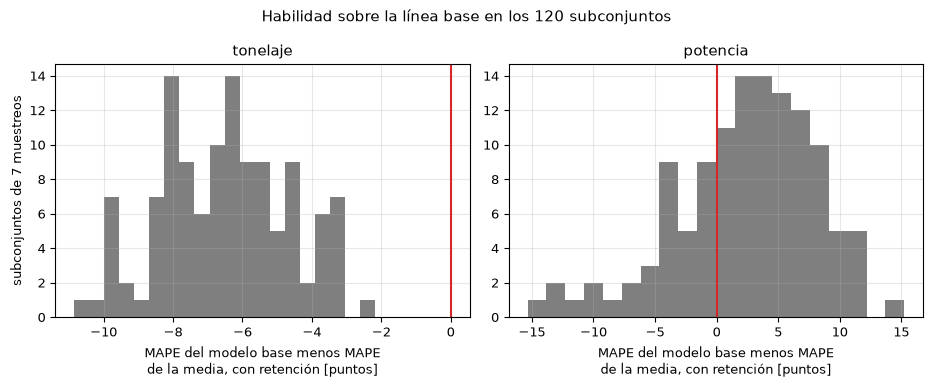

In [6]:
# Histograma del margen del modelo base sobre la media constante en los 120 subconjuntos, por objetivo
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9))
for ax, key, label in zip(axes, ("tph", "kW"), ("tonelaje", "potencia")):
    ax.hist(margin[key, "constant_mean"], bins=20, color="tab:grey")
    ax.axvline(0, color="tab:red", lw=1.5)
    ax.set_xlabel("MAPE del modelo base menos MAPE\nde la media, con retención [puntos]")
    ax.set_title(label)
axes[0].set_ylabel("subconjuntos de 7 muestreos")
fig.suptitle("Habilidad sobre la línea base en los 120 subconjuntos")
fig.tight_layout()
plt.show()

La habilidad de tonelaje es robusta: el modelo base supera a la media constante en los 120 subconjuntos, y el histograma de su margen queda por completo a la izquierda de cero, de modo que ninguna elección de siete muestreos lo hace perder frente a la línea base. Frente a la regresión libre gana en 80 de 120, exactamente dos tercios, una mayoría modesta que concuerda con el empate con diez muestreos: la física no tiene una ventaja decisiva sobre una regresión en la abertura, solo la de ser un modelo. La habilidad de potencia no es robusta: el modelo base supera a la media en solo 36 de los 120 subconjuntos, es decir, pierde en 84, y supera a la regresión libre en 10. La figura muestra que el histograma de potencia atraviesa el cero con la mayor parte de su masa del lado perdedor. La afirmación BS-1 es sobre el tonelaje y sobre el protocolo, y los 120 subconjuntos miden ambos; el traslape de los subconjuntos hace que esto sea una afirmación sobre la sensibilidad a la elección de siete muestreos, y haría falta un conjunto mayor de muestreos para decir más.

**Prueba 2, la banda predictiva, dentro de la muestra y anidada.** CrusherCal envuelve la predicción con retención del modelo base en una banda de 80 por ciento, $\hat y \pm 1{,}2816\,\sigma$, con $\sigma$ la desviación estándar muestral de los residuos con retención (`predictive_band`; el factor 1,2816 es el cuantil normal bilateral de 80 por ciento). La cobertura de esa banda puede medirse de dos maneras, y responden preguntas distintas. La primera, llamada dentro de la muestra, calcula $\sigma$ con los diez residuos con retención y luego pregunta cuántos de esos mismos diez residuos caen dentro de la banda: $\sigma$ ha visto los mismos residuos con los que se la verifica. La segunda, llamada anidada, es fuera de la muestra: para el muestreo $i$, $\sigma_i$ sale solo de los residuos con retención de los otros nueve muestreos (`nested_band_coverage`), y el muestreo $i$ queda cubierto cuando su propio residuo está dentro de $1{,}2816\,\sigma_i$. Fuera de la muestra tiene aquí una salvedad: cada residuo con retención que fija $\sigma_i$ sale de un pliegue ajustado con todos los muestreos menos el suyo, así que el muestreo $i$ está dentro de los ajustes que originan los residuos que fijan su banda, a través de lo que cada pliegue reajusta (un escalar para el tonelaje, dos coeficientes para la potencia); la fuga es de segundo orden y no se elimina. La primera celda construye la banda dentro de la muestra para ambos objetivos desde las predicciones con retención del documento vivo.

In [7]:
# La banda de 80 % dentro de la muestra: sigma de los diez residuos con retención, y la parte de ellos que queda dentro
resid = {key: np.array(doc["loo"][key]["measured"]) - np.array(doc["loo"][key]["strict"]["pred"]["M0"])
         for key in ("tph", "kW")}
print("factor de la banda de 80 %:", loo.band_factor(0.8))
for key, label in (("tph", "tonelaje [t/h]"), ("kW", "potencia [kW]")):
    band = loo.predictive_band(resid[key])
    inside = np.abs(resid[key]) <= band["halfwidth"]
    print(f"{label:16s} sigma {band['sigma']:7.2f}  semiancho {band['halfwidth']:7.2f}", end="  ")
    print(f"cobertura {inside.mean():.2f}", end="  ")
    print("fuera: muestreo", np.flatnonzero(~inside) + 1)

factor de la banda de 80 %: 1.2816
tonelaje [t/h]   sigma  186.09  semiancho  238.50  cobertura 0.90  fuera: muestreo [1]
potencia [kW]    sigma   81.98  semiancho  105.06  cobertura 0.90  fuera: muestreo [7]


La segunda celda mide la cobertura anidada con `loo.nested_band_coverage`: el sigma que le habrían dado a cada muestreo los otros nueve, y el veredicto para cada muestreo.

In [8]:
# La cobertura anidada fuera de la muestra: sigma de cada muestreo solo con los otros nueve residuos
nested = {key: loo.nested_band_coverage(resid[key]) for key in ("tph", "kW")}
for key, label in (("tph", "tonelaje [t/h]"), ("kW", "potencia [kW]")):
    outside = np.flatnonzero(~np.array(nested[key]["covered"])) + 1
    print(f"{label:16s} sigma de los otros nueve, por muestreo:", np.round(nested[key]["sigma"], 1))
    print(f"{'':16s} cobertura anidada {nested[key]['coverage']:.2f}  fuera: muestreo {outside}")

tonelaje [t/h]   sigma de los otros nueve, por muestreo: [123.2 197.3 195.1 189.4 196.6 178.2 195.7 196.6 179.5 196.6]
                 cobertura anidada 0.80  fuera: muestreo [1 6]
potencia [kW]    sigma de los otros nueve, por muestreo: [83.6 84.7 86.8 81.2 80.4 81.5 69.4 86.5 82.5 81.9]
                 cobertura anidada 0.90  fuera: muestreo [7]


La figura dibuja, para el tonelaje, la predicción con retención de cada muestreo con sus dos bandas, la banda dentro de la muestra de un semiancho fijo y la banda anidada cuyo semiancho cambia con el sigma de los otros nueve, frente a la medición.

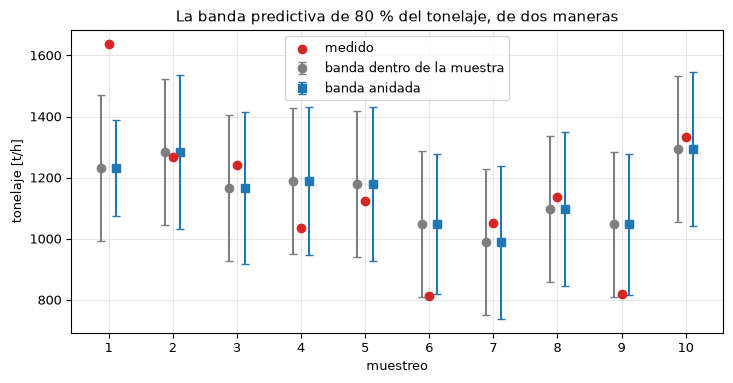

In [9]:
# Las diez mediciones frente a las predicciones con retención con la banda dentro de la muestra y la anidada, tonelaje
held = np.array(doc["loo"]["tph"]["strict"]["pred"]["M0"])
truth = np.array(doc["loo"]["tph"]["measured"])
fixed = loo.predictive_band(resid["tph"])["halfwidth"]
nested_half = loo.band_factor(0.8) * np.array(nested["tph"]["sigma"])
x = np.arange(1, 11)
fig, ax = plt.subplots()
ax.errorbar(x - 0.12, held, yerr=fixed, fmt="o", capsize=3, color="tab:grey", label="banda dentro de la muestra")
ax.errorbar(x + 0.12, held, yerr=nested_half, fmt="s", capsize=3, color="tab:blue", label="banda anidada")
ax.scatter(x, truth, color="tab:red", zorder=3, label="medido")
ax.set_xticks(x)
ax.set_xlabel("muestreo")
ax.set_ylabel("tonelaje [t/h]")
ax.set_title("La banda predictiva de 80 % del tonelaje, de dos maneras")
ax.legend()
fig.tight_layout()
plt.show()

Las dos coberturas difieren en el tonelaje, y la diferencia es el punto. Dentro de la muestra, nueve de los diez muestreos caen dentro de la banda (0,90, solo el muestreo 1 afuera), porque $\sigma$ = 186,09 t/h se calculó con el residuo del propio muestreo 1 entre los diez. Anidada, solo ocho lo hacen (0,80, muestreos 1 y 6 afuera): los otros nueve residuos le dan al muestreo 1 un $\sigma$ de apenas 123,2 t/h, porque el muestreo más difícil de predecir ya no está en la muestra que dimensiona su banda, y su residuo de 407 t/h queda muy fuera de la banda más angosta. El 0,90 dentro de la muestra es el optimismo que este notebook existe para exponer, y no es la cifra que debe leerse como calibración; el 0,80 anidado es la cobertura fuera de la muestra, e iguala el nivel nominal. La banda no es pequeña: su semiancho dentro de la muestra de 238,50 t/h le dice al usuario que el próximo muestreo estará en cualquier punto de un rango de 477 t/h, lo que es honesto para un modelo que solo conoce la abertura. Para la potencia las dos coberturas coinciden en 0,90, con el muestreo 7 afuera en ambas (los otros nueve le dan un $\sigma$ de 69,4 kW frente a 81,98 kW con él), y el semiancho de 105,06 kW es amplio para una cantidad que el notebook 02 del tema 05 midió entre 187 y 355 kW, que es lo que parece la ausencia de habilidad.

Con diez muestreos la cobertura solo puede tomar los valores 0, 0,1, ... 1, así que ambos números son gruesos. Si la banda estuviera exactamente calibrada, el número de muestreos dentro de ella seguiría una ley binomial con $n = 10$ y $p = 0,8$. La celda calcula la probabilidad de cada conteo observado bajo esa ley, y la probabilidad de un conteo al menos tan extremo.

In [10]:
# Referencia binomial para una banda de 80 % exactamente calibrada: la probabilidad de los conteos observados
pmf = [math.comb(10, k) * 0.8 ** k * 0.2 ** (10 - k) for k in range(11)]
for key, label in (("tph", "tonelaje"), ("kW", "potencia")):
    half = loo.predictive_band(resid[key])["halfwidth"]
    inside = float(np.mean(np.abs(resid[key]) <= half))
    for kind, coverage in (("dentro de la muestra", inside), ("anidada", nested[key]["coverage"])):
        k = round(coverage * 10)
        print(f"{label:10s} {kind:20s} {k} de 10: P(conteo = {k}) = {pmf[k]:.4f},", end=" ")
        print(f"P(conteo >= {k}) = {sum(pmf[k:]):.4f}, P(conteo <= {k}) = {sum(pmf[:k + 1]):.4f}")

tonelaje   dentro de la muestra 9 de 10: P(conteo = 9) = 0.2684, P(conteo >= 9) = 0.3758, P(conteo <= 9) = 0.8926
tonelaje   anidada              8 de 10: P(conteo = 8) = 0.3020, P(conteo >= 8) = 0.6778, P(conteo <= 8) = 0.6242
potencia   dentro de la muestra 9 de 10: P(conteo = 9) = 0.2684, P(conteo >= 9) = 0.3758, P(conteo <= 9) = 0.8926
potencia   anidada              9 de 10: P(conteo = 9) = 0.2684, P(conteo >= 9) = 0.3758, P(conteo <= 9) = 0.8926


Con una banda de 80 por ciento exactamente calibrada, 9 muestreos de 10 dentro tiene probabilidad 0,2684 (0,3758 para 9 o más) y 8 de 10 tiene 0,3020 (0,6778 para 8 o más, 0,6242 para 8 o menos). Todo conteo que observaron las celdas, 8 o 9, es un resultado ordinario de una banda calibrada, de modo que los datos no pueden distinguir esta banda de una exactamente calibrada. Tampoco pueden distinguirla de una banda de cobertura verdadera algo distinta, pues con diez muestreos la binomial es ancha. El enunciado honesto es que la cobertura fuera de la muestra, 0,80 en el tonelaje y 0,90 en la potencia, es consistente con el 0,80 nominal y que diez muestreos no pueden establecerla con más precisión. Esta lectura reemplaza a la que toma el 0,90 dentro de la muestra por una calibración, y es la razón por la que el producto informa las dos coberturas por separado.

## Resultados

**Respuesta:** sí en el tonelaje, dentro de los límites de diez muestreos, y no en la potencia. El protocolo con retención revierte dos conclusiones del protocolo dentro de la muestra: elimina la ventaja aparente de una regresión libre sobre el modelo base de tonelaje (8,24 frente a 10,95 por ciento dentro de la muestra, 12,18 frente a 12,09 con retención) y elimina la habilidad aparente de la forma de potencia (19,28 frente a 22,03 por ciento dentro de la muestra, 25,94 frente a 24,48 con retención). La habilidad de tonelaje sobrevive al remuestreo: el modelo base con retención supera a la media constante en 120 de los 120 subconjuntos de siete muestreos, todos enumerados sin repeticiones, y a la regresión libre en 80 de 120, mientras que en la potencia supera a la media en solo 36 y a la regresión en 10. La banda de 80 por ciento se informa dos veces y no deben confundirse: su cobertura dentro de la muestra es 0,90 en ambos objetivos, con el sigma tomado de los mismos diez residuos con que se la verifica; su cobertura anidada fuera de la muestra, con el sigma de cada muestreo tomado de los otros nueve, es 0,80 en el tonelaje y 0,90 en la potencia. Que 8 o más muestreos de 10 queden dentro de la banda tiene probabilidad 0,6778 bajo una banda exactamente calibrada, así que la cobertura fuera de la muestra es consistente con el nivel nominal y diez muestreos no pueden decir más.

Para la afirmación BS-1 esta es la evidencia: validación con retención con controles y una banda, medida aquí, con el error con retención del modelo base, 12,09 por ciento, cercano a los 11,55 por ciento del mismo modelo base dentro de la muestra y muy por debajo de los 18,29 por ciento de la línea base, el fracaso del residuo acotado en superar al modelo base (13,45 por ciento) informado como la hipótesis nula preregistrada que es, y el control de barajado con la semilla 42, 25,04 por ciento, un solo sorteo que el notebook 02 repite con 200 semillas. Lo que el notebook no muestra es la entrega en el navegador de la afirmación, cubierta por las pruebas de la propia aplicación; una comparación con una banda del artículo, para la cual este repositorio no tiene fuente; ni la generalización a otro chancador o mena, que diez muestreos de una máquina no pueden dar. Y la potencia sigue siendo un negativo honesto, que el producto no afirma.

## Resumen

BS-1 es una afirmación sobre el método, no sobre un error menor: la validación con retención, los controles ejecutados las veces suficientes y una banda predictiva cambian lo que puede concluirse de diez muestreos. Medido aquí, la retención elimina dos conclusiones falsas del protocolo dentro de la muestra, la habilidad de tonelaje sobrevive a cada uno de los 120 remuestreos de siete muestreos, y la cobertura fuera de la muestra de la banda, la anidada, es consistente con su nivel nominal, mientras que la cobertura dentro de la muestra no debe leerse como calibración y la potencia sigue sin predecirse. El tema siguiente se vuelve a los modelos aprendidos y a la misma disciplina aplicada a ellos.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026